# Fase 9: Análisis de error por equipo
**Tesis:** Modelo Predictivo de Resultados — Premier League 2017–2025
**Objetivo:** Responder **con qué equipos se equivoca más el modelo, con cuáles acierta mejor, y por qué**.
**Input:** predicciones fuera de muestra de los 7 folds (2018/19–2024/25, recalculadas con los hiperparámetros ya elegidos) y de la prueba real 2025/26 (`10_prueba_real_2025_26.ipynb`): **3.003 partidos**.
**Output:** `resultados/analisis_error_*.csv`, `Imagenes/analisis_error/*.png`

## Modelos analizados
- **Random Forest** (configuración final del informe, con `class_weight='balanced'`).
- **Solo cuotas**: regresión logística sobre las 3 probabilidades implícitas. Sirve para separar qué errores son del modelo y cuáles vienen del propio mercado.
- **Mercado (regla simple)**: local si P(local) > P(visitante).

## Cómo leer los resultados (importante)
- Un **acierto** es predecir bien si el local gana (1) o no (0); el empate cuenta como "no gana el local".
- Cada equipo tiene entre ~35 y ~270 partidos. Con 100 partidos el accuracy tiene un error estándar de ±4,7 puntos, y entre ~30 equipos algunos saldrán "mejores" o "peores" **solo por azar**. Por eso se reportan intervalos de confianza y se corrige por comparaciones múltiples (Benjamini-Hochberg). Los equipos con menos de 60 partidos se marcan y no se ordenan.
- Como el modelo sigue casi siempre a las cuotas, los "errores por equipo" son en buena parte **los errores del mercado**.

## 1. Predicciones fuera de muestra: 7 folds + 2025/26

In [1]:
import os, sys, ast, warnings
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import binomtest
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, '.')
from utils.split_utils import expanding_window_split
sns.set_theme(style='whitegrid', palette='muted'); plt.rcParams['figure.dpi'] = 120
os.makedirs('Imagenes/analisis_error', exist_ok=True)
TARGET = 'target_home_win'

sel = pd.read_csv('Dataset/model_dataset_selected.csv'); enr = pd.read_csv('Dataset/model_dataset_enriched.csv')
assert len(sel) == len(enr) and (sel[TARGET].values == enr[TARGET].values).all()
X, y = sel.drop(columns=[TARGET, 'season']), sel[TARGET]
CUOTAS = enr[['odds_home_prob', 'odds_draw_prob', 'odds_away_prob']]
res = pd.read_csv('Dataset/model_dataset.csv')[['season', 'home', 'away', 'home_goals', 'away_goals', 'result']]
folds = expanding_window_split(sel, season_col='season', min_train_seasons=1)

tun = pd.read_csv('resultados/tuning_results_detailed.csv'); tun_rf = tun[tun.model == 'Random Forest'].set_index('fold')
hp = pd.read_csv('resultados/mezcla_modelos_hiperparametros.csv'); hp_c = hp[hp.modelo == 'Solo cuotas'].set_index('fold')['logisticregression__C']

filas = []
for k, (tr, te, _, temp) in enumerate(folds, 1):
    params = ast.literal_eval(tun_rf.loc[k, 'best_params'])
    rf = RandomForestClassifier(random_state=42, n_jobs=-1, class_weight='balanced', **params).fit(X.iloc[tr], y.iloc[tr])
    p_rf = rf.predict_proba(X.iloc[te])[:, 1]
    lr = make_pipeline(StandardScaler(), LogisticRegression(C=hp_c[k], max_iter=2000)).fit(CUOTAS.iloc[tr], y.iloc[tr])
    p_cu = lr.predict_proba(CUOTAS.iloc[te])[:, 1]
    # control: reproduce la accuracy de 04_tuning.ipynb para este fold
    acc = ((p_rf >= .5).astype(int) == y.iloc[te].values).mean()
    assert abs(acc - tun_rf.loc[k, 'accuracy']) < 0.003, f'fold {k}: {acc:.4f} vs {tun_rf.loc[k, "accuracy"]:.4f}'
    d = enr.iloc[te][['season', 'date', 'home', 'away', 'odds_home_prob', 'odds_away_prob']].copy()
    d['y'], d['p_rf'], d['p_cu'] = y.iloc[te].values, p_rf, p_cu
    filas.append(d)
oof = pd.concat(filas, ignore_index=True)
print(f'7 folds: {len(oof)} partidos reproducidos (accuracy del Random Forest coincide con 04_tuning en cada fold)')

real = pd.read_csv('resultados/prueba_real_2025_26_predicciones.csv')
real = real.assign(season='2025-2026', y=real[TARGET], p_cu=real['p_cuotas'])[['season', 'date', 'home', 'away', 'odds_home_prob', 'y', 'p_rf', 'p_cu']]
real['odds_away_prob'] = pd.read_csv('resultados/prueba_real_2025_26_predicciones.csv')['odds_away_prob'].values
df = pd.concat([oof.merge(res, on=['season', 'home', 'away'], how='left'), real.merge(pd.read_csv('resultados/prueba_real_2025_26_predicciones.csv')[['home', 'away', 'home_goals', 'away_goals', 'result']], on=['home', 'away'], how='left')], ignore_index=True)
assert df.result.notna().all() and len(df) == 3003
df['pred_rf'] = (df.p_rf >= .5).astype(int); df['pred_cu'] = (df.p_cu >= .5).astype(int); df['pred_mer'] = (df.odds_home_prob > df.odds_away_prob).astype(int)
for c in ('rf', 'cu', 'mer'): df['ok_' + c] = (df['pred_' + c] == df.y).astype(int)
df.to_csv('resultados/predicciones_7folds_y_2025_26.csv', index=False)
print(f'Total: {len(df)} partidos ({df.season.nunique()} temporadas) | accuracy: RF {df.ok_rf.mean():.4f} | solo cuotas {df.ok_cu.mean():.4f} | mercado {df.ok_mer.mean():.4f}')

7 folds: 2626 partidos reproducidos (accuracy del Random Forest coincide con 04_tuning en cada fold)
Total: 3003 partidos (8 temporadas) | accuracy: RF 0.6737 | solo cuotas 0.6787 | mercado 0.6384


## 2. ¿Dónde se concentran los errores? Por tipo de resultado real
El problema es "¿gana el local?": un empate o una victoria visitante son ambos la clase 0.

In [2]:
por_res = df.groupby('result')[['ok_rf', 'ok_cu', 'ok_mer']].mean().round(3); por_res.columns = ['Random Forest', 'Solo cuotas', 'Mercado']
por_res.insert(0, 'partidos', df.groupby('result').size()); por_res.index = por_res.index.map({'H': 'Gana local (H)', 'D': 'Empate (D)', 'A': 'Gana visitante (A)'})
print(por_res.to_string())
err = df[df.ok_rf == 0]
print('\nComposición de los errores del Random Forest:')
print(err.result.map({'H': 'el local ganó y el modelo dijo "no"', 'D': 'hubo empate y el modelo dijo "gana local"', 'A': 'ganó el visitante y el modelo dijo "gana local"'}).value_counts(normalize=True).round(3).to_string())
por_res.to_csv('resultados/analisis_error_por_resultado.csv')

                    partidos  Random Forest  Solo cuotas  Mercado
result                                                           
Gana visitante (A)       997          0.789        0.831    0.601
Empate (D)               691          0.644        0.671    0.389
Gana local (H)          1315          0.602        0.567    0.798

Composición de los errores del Random Forest:
result
el local ganó y el modelo dijo "no"                0.535
hubo empate y el modelo dijo "gana local"          0.251
ganó el visitante y el modelo dijo "gana local"    0.214


## 3. Errores compartidos con el mercado
Si el modelo falla en los mismos partidos que la regla del mercado, el error no es del modelo sino de la información disponible.

In [3]:
t = pd.crosstab(df.ok_rf.map({1: 'RF acierta', 0: 'RF falla'}), df.ok_mer.map({1: 'Mercado acierta', 0: 'Mercado falla'}))
print(t.to_string()); print()
print(f'De los {int((df.ok_rf == 0).sum())} errores del Random Forest, el mercado también falla en {int(((df.ok_rf == 0) & (df.ok_mer == 0)).sum())} ({((df.ok_rf == 0) & (df.ok_mer == 0)).sum() / (df.ok_rf == 0).sum() * 100:.0f}%).')
c = pd.crosstab(df.ok_rf, df.ok_cu); print(f'Random Forest y "solo cuotas" coinciden (ambos aciertan o ambos fallan) en el {(df.ok_rf == df.ok_cu).mean() * 100:.0f}% de los partidos.')

ok_mer      Mercado acierta  Mercado falla
ok_rf                                     
RF acierta             1647            376
RF falla                270            710

De los 980 errores del Random Forest, el mercado también falla en 710 (72%).
Random Forest y "solo cuotas" coinciden (ambos aciertan o ambos fallan) en el 93% de los partidos.


## 4. Por equipo
Cada equipo se mira en los partidos que jugó como **local o visitante**. Además del accuracy se calcula la **sorpresa media**: cuánto mejor (o peor) le fue al equipo de lo que esperaba el modelo calibrado sobre cuotas. Valor positivo = el equipo rinde más de lo que el mercado espera; negativo = menos.

In [4]:
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z**2 / n; c = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

h = df.assign(equipo=df.home, lado='local', sorpresa=df.y - df.p_cu)
a = df.assign(equipo=df.away, lado='visitante', sorpresa=df.p_cu - df.y)
v = pd.concat([h, a], ignore_index=True)

p0 = df.ok_rf.mean()
filas = []
for eq, g in v.groupby('equipo'):
    n = len(g); k = int(g.ok_rf.sum()); lo, hi = wilson(k, n)
    gl, gv = g[g.lado == 'local'], g[g.lado == 'visitante']
    s, se = g.sorpresa.mean(), g.sorpresa.std(ddof=1) / np.sqrt(n)
    filas.append({'equipo': eq, 'partidos': n, 'temporadas': g.season.nunique(), 'acc_rf': k / n, 'ic_inf': lo, 'ic_sup': hi, 'acc_cuotas': g.ok_cu.mean(), 'acc_mercado': g.ok_mer.mean(),
                  'dif_rf_vs_mercado_pp': (g.ok_rf.mean() - g.ok_mer.mean()) * 100, 'n_local': len(gl), 'acc_rf_local': gl.ok_rf.mean(), 'n_visitante': len(gv), 'acc_rf_visitante': gv.ok_rf.mean(),
                  'sorpresa_media': s, 'sorpresa_ic_inf': s - 1.96 * se, 'sorpresa_ic_sup': s + 1.96 * se, 'p_valor_vs_global': binomtest(k, n, p0).pvalue})
T = pd.DataFrame(filas)
# corrección por comparaciones múltiples (Benjamini-Hochberg)
o = T.p_valor_vs_global.argsort().values; m = len(T); q = np.empty(m); r = T.p_valor_vs_global.values[o] * m / np.arange(1, m + 1)
q[o] = np.minimum.accumulate(r[::-1])[::-1].clip(max=1); T['q_valor_BH'] = q
T['n_suficiente'] = T.partidos >= 60
T = T.sort_values('acc_rf', ascending=False).reset_index(drop=True)
T.round(4).to_csv('resultados/analisis_error_equipos.csv', index=False)
print(f'Accuracy global del Random Forest: {p0:.4f} | equipos: {len(T)} | equipos con < 60 partidos: {int((~T.n_suficiente).sum())} ({", ".join(T[~T.n_suficiente].equipo)})')
mostrar = ['equipo', 'partidos', 'temporadas', 'acc_rf', 'ic_inf', 'ic_sup', 'acc_mercado', 'dif_rf_vs_mercado_pp', 'acc_rf_local', 'acc_rf_visitante', 'q_valor_BH']
print(T[T.n_suficiente][mostrar].round(3).to_string(index=False))

Accuracy global del Random Forest: 0.6737 | equipos: 30 | equipos con < 60 partidos: 6 (Huddersfield Town, West Brom, Luton Town, Cardiff City, Ipswich Town, Sunderland)
           equipo  partidos  temporadas  acc_rf  ic_inf  ic_sup  acc_mercado  dif_rf_vs_mercado_pp  acc_rf_local  acc_rf_visitante  q_valor_BH
  Manchester City       302           8   0.791   0.742   0.833        0.791                 0.000         0.775             0.808       0.000
        Liverpool       301           8   0.767   0.717   0.812        0.771                -0.332         0.753             0.781       0.007
     Norwich City        73           2   0.767   0.658   0.849        0.753                 1.370         0.833             0.703       0.446
          Arsenal       303           8   0.719   0.666   0.767        0.719                 0.000         0.678             0.762       0.446
  West Ham United       301           8   0.694   0.640   0.744        0.645                 4.983         0.711   

In [5]:
S = T[T.n_suficiente]
print('MEJOR acierto del Random Forest (equipos con >= 60 partidos):'); print(S.head(5)[['equipo', 'partidos', 'acc_rf', 'ic_inf', 'ic_sup', 'q_valor_BH']].round(3).to_string(index=False))
print('\nPEOR acierto:'); print(S.tail(5).iloc[::-1][['equipo', 'partidos', 'acc_rf', 'ic_inf', 'ic_sup', 'q_valor_BH']].round(3).to_string(index=False))
sig = S[S.q_valor_BH < 0.05]
print(f'\nEquipos cuya diferencia con el accuracy global NO se explica por azar (q < 0,05): {len(sig)}', '->', ', '.join(sig.equipo) if len(sig) else 'ninguno')
rango = S.acc_rf.max() - S.acc_rf.min(); esperado = 1.96 * np.sqrt(p0 * (1 - p0) / S.partidos.median())
print(f'Rango observado entre equipos: {rango * 100:.1f} pp | variación esperada solo por azar con n={int(S.partidos.median())}: ±{esperado * 100:.1f} pp')

MEJOR acierto del Random Forest (equipos con >= 60 partidos):
         equipo  partidos  acc_rf  ic_inf  ic_sup  q_valor_BH
Manchester City       302   0.791   0.742   0.833       0.000
      Liverpool       301   0.767   0.717   0.812       0.007
   Norwich City        73   0.767   0.658   0.849       0.446
        Arsenal       303   0.719   0.666   0.767       0.446
West Ham United       301   0.694   0.640   0.744       0.989

PEOR acierto:
           equipo  partidos  acc_rf  ic_inf  ic_sup  q_valor_BH
      Aston Villa       262   0.599   0.539   0.657       0.073
         Brighton       303   0.604   0.548   0.657       0.073
Nottingham Forest       149   0.617   0.537   0.692       0.451
        Brentford       186   0.624   0.552   0.690       0.451
   Manchester Utd       304   0.635   0.579   0.687       0.451

Equipos cuya diferencia con el accuracy global NO se explica por azar (q < 0,05): 2 -> Manchester City, Liverpool
Rango observado entre equipos: 19.2 pp | variación e

### ¿Qué equipos rinden más o menos de lo que espera el mercado?
Es el análisis más informativo: un equipo con sorpresa positiva sistemática es **subestimado** por las cuotas (y por el modelo, que las sigue).

In [6]:
Ssor = S.sort_values('sorpresa_media', ascending=False)
sig_s = Ssor[(Ssor.sorpresa_ic_inf > 0) | (Ssor.sorpresa_ic_sup < 0)]
print('Sorpresa media (positivo = rinde MÁS de lo que esperaba el mercado), equipos con intervalo que excluye 0:')
print(sig_s[['equipo', 'partidos', 'sorpresa_media', 'sorpresa_ic_inf', 'sorpresa_ic_sup', 'acc_rf']].round(3).to_string(index=False) if len(sig_s) else 'ninguno')
print('\nTop 5 sobre expectativa:'); print(Ssor.head(5)[['equipo', 'partidos', 'sorpresa_media', 'acc_rf']].round(3).to_string(index=False))
print('\nTop 5 bajo expectativa:'); print(Ssor.tail(5).iloc[::-1][['equipo', 'partidos', 'sorpresa_media', 'acc_rf']].round(3).to_string(index=False))

Sorpresa media (positivo = rinde MÁS de lo que esperaba el mercado), equipos con intervalo que excluye 0:
     equipo  partidos  sorpresa_media  sorpresa_ic_inf  sorpresa_ic_sup  acc_rf
Southampton       228          -0.066           -0.124           -0.007   0.675
    Chelsea       302          -0.078           -0.130           -0.025   0.669

Top 5 sobre expectativa:
          equipo  partidos  sorpresa_media  acc_rf
Newcastle United       301           0.042   0.651
     Aston Villa       262           0.040   0.599
         Arsenal       303           0.035   0.719
       Liverpool       301           0.033   0.767
  Crystal Palace       301           0.018   0.674

Top 5 bajo expectativa:
      equipo  partidos  sorpresa_media  acc_rf
Norwich City        73          -0.089   0.767
     Chelsea       302          -0.078   0.669
 Southampton       228          -0.066   0.675
     Watford       114          -0.048   0.693
Leeds United       149          -0.033   0.691


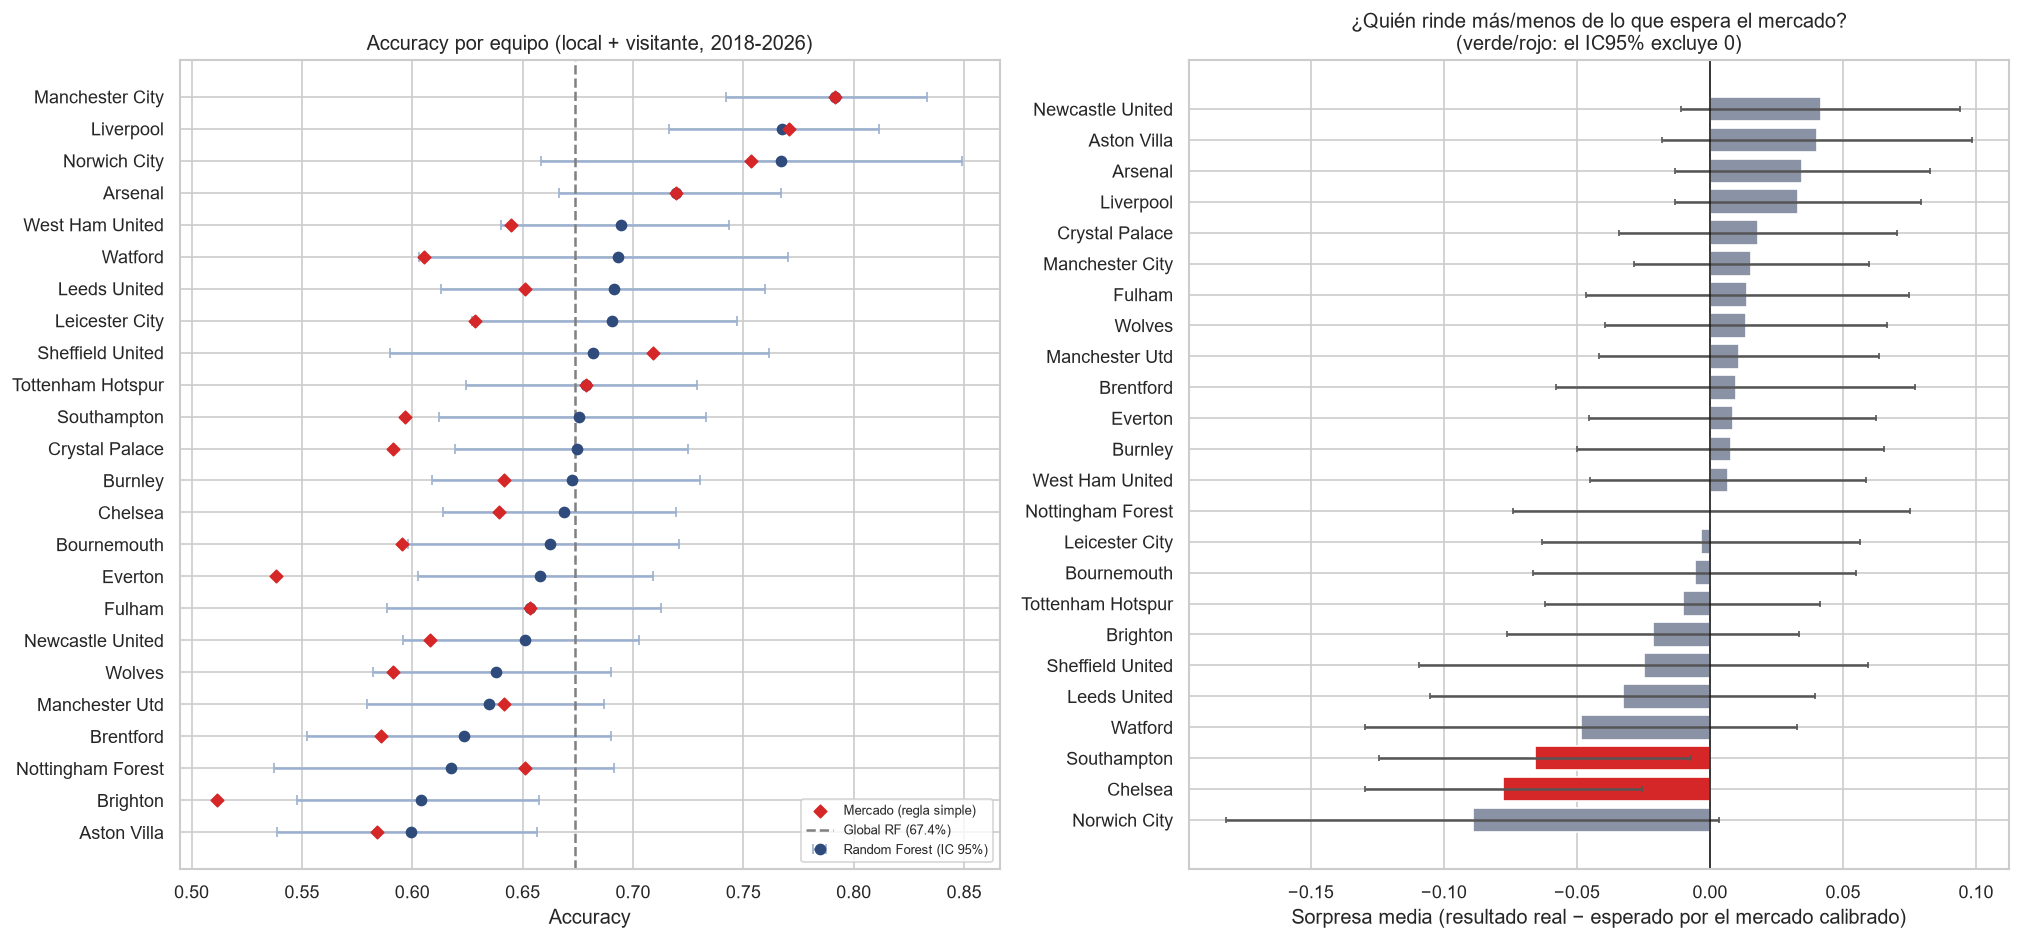

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(17, 8))
ax = axes[0]; d = S.sort_values('acc_rf'); yy = np.arange(len(d))
ax.errorbar(d.acc_rf, yy, xerr=[d.acc_rf - d.ic_inf, d.ic_sup - d.acc_rf], fmt='o', color='#2F4B7C', ecolor='#9bb0d1', capsize=3, label='Random Forest (IC 95%)')
ax.scatter(d.acc_mercado, yy, marker='D', color='#d62728', s=28, label='Mercado (regla simple)', zorder=3)
ax.axvline(p0, color='gray', ls='--', label=f'Global RF ({p0 * 100:.1f}%)'); ax.set_yticks(yy); ax.set_yticklabels(d.equipo)
ax.set_xlabel('Accuracy'); ax.set_title('Accuracy por equipo (local + visitante, 2018-2026)'); ax.legend(loc='lower right', fontsize=8)
ax = axes[1]; d = S.sort_values('sorpresa_media'); yy = np.arange(len(d))
col = ['#2E7D5B' if lo > 0 else '#d62728' if hi < 0 else '#8A93A6' for lo, hi in zip(d.sorpresa_ic_inf, d.sorpresa_ic_sup)]
ax.barh(yy, d.sorpresa_media, xerr=[d.sorpresa_media - d.sorpresa_ic_inf, d.sorpresa_ic_sup - d.sorpresa_media], color=col, ecolor='#555', capsize=2)
ax.axvline(0, color='k', lw=1); ax.set_yticks(yy); ax.set_yticklabels(d.equipo); ax.set_xlabel('Sorpresa media (resultado real − esperado por el mercado calibrado)')
ax.set_title('¿Quién rinde más/menos de lo que espera el mercado?\n(verde/rojo: el IC95% excluye 0)')
plt.tight_layout(); plt.savefig('Imagenes/analisis_error/por_equipo.png', bbox_inches='tight', dpi=120); plt.show()

### ¿Es lo mismo como local que como visitante?

In [8]:
loc_vis = S[['equipo', 'n_local', 'acc_rf_local', 'n_visitante', 'acc_rf_visitante']].copy(); loc_vis['dif_pp'] = (loc_vis.acc_rf_local - loc_vis.acc_rf_visitante) * 100
print(f'Accuracy del RF cuando el equipo juega de local: {df.ok_rf.mean() * 100:.1f}% (todos los partidos; cada partido tiene un local y un visitante)')
print(loc_vis.sort_values('dif_pp').round(3).to_string(index=False))
print(f'\nCorrelación entre accuracy como local y como visitante entre equipos: {loc_vis.acc_rf_local.corr(loc_vis.acc_rf_visitante):.2f}')

Accuracy del RF cuando el equipo juega de local: 67.4% (todos los partidos; cada partido tiene un local y un visitante)
           equipo  n_local  acc_rf_local  n_visitante  acc_rf_visitante  dif_pp
           Fulham      111         0.595          111             0.712 -11.712
          Arsenal      152         0.678          151             0.762  -8.396
          Chelsea      151         0.629          151             0.709  -7.947
 Newcastle United      151         0.616          150             0.687  -7.077
         Brighton      151         0.570          152             0.638  -6.862
      Bournemouth      112         0.634          113             0.690  -5.634
   Manchester Utd      152         0.612          152             0.658  -4.605
Nottingham Forest       75         0.600           74             0.635  -3.514
  Manchester City      151         0.775          151             0.808  -3.311
      Aston Villa      130         0.585          132             0.614  -2.902


## 5. Por temporada y por tipo de partido (favorito del mercado)

In [9]:
por_temp = df.groupby('season')[['ok_rf', 'ok_cu', 'ok_mer']].mean().round(3); por_temp.columns = ['Random Forest', 'Solo cuotas', 'Mercado']
por_temp.insert(0, 'partidos', df.groupby('season').size()); por_temp['empates_%'] = (df.assign(e=(df.result == 'D')).groupby('season').e.mean() * 100).round(1)
por_temp['local_gana_%'] = (df.groupby('season').y.mean() * 100).round(1); print(por_temp.to_string())
por_temp.to_csv('resultados/analisis_error_por_temporada.csv')
df['tipo'] = pd.cut(df.odds_home_prob, [0, .30, .45, .60, .75, 1], labels=['visitante muy favorito (<30%)', 'visitante favorito (30-45%)', 'parejo (45-60%)', 'local favorito (60-75%)', 'local muy favorito (>75%)'])
por_tipo = df.groupby('tipo', observed=True).agg(partidos=('ok_rf', 'size'), local_gana=('y', 'mean'), prob_media_modelo=('p_rf', 'mean'), RF=('ok_rf', 'mean'), Cuotas=('ok_cu', 'mean'), Mercado=('ok_mer', 'mean')).round(3)
print('\nPor tipo de partido según la cuota del local:'); print(por_tipo.to_string()); por_tipo.to_csv('resultados/analisis_error_por_favorito.csv')

           partidos  Random Forest  Solo cuotas  Mercado  empates_%  local_gana_%
season                                                                           
2018-2019       371          0.687        0.712    0.633       18.1          47.7
2019-2020       371          0.658        0.663    0.606       24.5          45.0
2020-2021       377          0.687        0.700    0.623       22.0          37.7
2021-2022       377          0.695        0.687    0.671       22.8          43.0
2022-2023       377          0.679        0.676    0.660       22.8          48.3
2023-2024       376          0.691        0.694    0.676       21.8          45.7
2024-2025       377          0.679        0.668    0.631       24.4          40.8
2025-2026       377          0.613        0.629    0.605       27.6          42.2

Por tipo de partido según la cuota del local:
                               partidos  local_gana  prob_media_modelo     RF  Cuotas  Mercado
tipo                                  

## 6. Los errores más confiados (sorpresas)

In [10]:
df['error_conf'] = np.abs(df.p_rf - df.y)
top = df[df.ok_rf == 0].sort_values('error_conf', ascending=False).head(15).copy()
top['marcador'] = top.home_goals.astype(int).astype(str) + '-' + top.away_goals.astype(int).astype(str)
print(top[['season', 'date', 'home', 'away', 'marcador', 'p_rf', 'odds_home_prob']].round(3).to_string(index=False))
top[['season', 'date', 'home', 'away', 'marcador', 'result', 'p_rf', 'p_cu', 'odds_home_prob']].round(3).to_csv('resultados/analisis_error_errores_confiados.csv', index=False)
print('\nEquipos que más aparecen entre los 60 errores más confiados (como local o visitante):')
t60 = df[df.ok_rf == 0].sort_values('error_conf', ascending=False).head(60)
print(pd.concat([t60.home, t60.away]).value_counts().head(8).to_string())

   season       date              home              away marcador  p_rf  odds_home_prob
2019-2020 2019-10-06   Manchester City            Wolves      0-2 0.909           0.893
2018-2019 2018-12-22   Manchester City    Crystal Palace      2-3 0.904           0.877
2022-2023 2022-08-15         Liverpool    Crystal Palace      1-1 0.870           0.847
2018-2019 2019-02-23           Burnley Tottenham Hotspur      2-1 0.135           0.174
2022-2023 2022-10-22 Nottingham Forest         Liverpool      1-0 0.136           0.091
2019-2020 2019-09-14      Norwich City   Manchester City      3-2 0.139           0.067
2022-2023 2023-02-04           Everton           Arsenal      1-0 0.147           0.118
2022-2023 2022-12-31   Manchester City           Everton      1-1 0.853           0.885
2021-2022 2021-12-28    Leicester City         Liverpool      1-0 0.148           0.125
2020-2021 2021-04-24         Liverpool  Newcastle United      1-1 0.846           0.820
2021-2022 2021-10-30   Mancheste

## 7. Resumen

In [11]:
print('=' * 80); print(' RESUMEN — ANÁLISIS DE ERROR'); print('=' * 80)
print(f' Partidos analizados: {len(df)} | accuracy RF {df.ok_rf.mean() * 100:.1f}% | solo cuotas {df.ok_cu.mean() * 100:.1f}% | mercado {df.ok_mer.mean() * 100:.1f}%')
print(f' El mercado también falla en el {((df.ok_rf == 0) & (df.ok_mer == 0)).sum() / (df.ok_rf == 0).sum() * 100:.0f}% de los errores del Random Forest')
print(f' Equipos con diferencia estadísticamente distinguible del azar (accuracy): {len(sig)} de {len(S)}')
print(f' Equipos con sorpresa significativa (rinden distinto de lo que espera el mercado): {len(sig_s)} de {len(S)}')
print('=' * 80)

 RESUMEN — ANÁLISIS DE ERROR
 Partidos analizados: 3003 | accuracy RF 67.4% | solo cuotas 67.9% | mercado 63.8%
 El mercado también falla en el 72% de los errores del Random Forest
 Equipos con diferencia estadísticamente distinguible del azar (accuracy): 2 de 24
 Equipos con sorpresa significativa (rinden distinto de lo que espera el mercado): 2 de 24
